In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [5]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)

df = student_performance.data.original

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [7]:
import requests
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url)
response.raise_for_status()

# Open the outer ZIP
outer_zip = zipfile.ZipFile(io.BytesIO(response.content))

print("Outer ZIP contents:", outer_zip.namelist())

# Open the inner ZIP
inner_zip = zipfile.ZipFile(
    io.BytesIO(outer_zip.read("student.zip"))
)

print("Inner ZIP contents:", inner_zip.namelist())

# Load the Mathematics CSV
with inner_zip.open("student-mat.csv") as file:
    df = pd.read_csv(file, sep=";")

print("\nMathematics dataset loaded!")
print("Shape:", df.shape)

df.head()

Outer ZIP contents: ['.student.zip_old', 'student.zip']
Inner ZIP contents: ['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']

Mathematics dataset loaded!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [8]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nColumn data types:")
print(df.dtypes)

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Duplicate rows: 0

Total missing values: 0

Column data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [10]:
print("DataFrame type:", type(df))

print("\nData types:")
print(df.dtypes.value_counts())

print("\nFirst row:")
print(df.iloc[0].to_dict())

DataFrame type: <class 'pandas.core.frame.DataFrame'>

Data types:
object    17
int64     16
Name: count, dtype: int64

First row:
{'school': 'GP', 'sex': 'F', 'age': 18, 'address': 'U', 'famsize': 'GT3', 'Pstatus': 'A', 'Medu': 4, 'Fedu': 4, 'Mjob': 'at_home', 'Fjob': 'teacher', 'reason': 'course', 'guardian': 'mother', 'traveltime': 2, 'studytime': 2, 'failures': 0, 'schoolsup': 'yes', 'famsup': 'no', 'paid': 'no', 'activities': 'no', 'nursery': 'yes', 'higher': 'yes', 'internet': 'no', 'romantic': 'no', 'famrel': 4, 'freetime': 3, 'goout': 4, 'Dalc': 1, 'Walc': 1, 'health': 3, 'absences': 6, 'G1': 5, 'G2': 6, 'G3': 6}


In [11]:
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumber of categorical columns:", len(categorical_cols))

print("\nNumerical columns:", numerical_cols)
print("\nNumber of numerical columns:", len(numerical_cols))

Categorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Number of categorical columns: 17

Numerical columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Number of numerical columns: 16


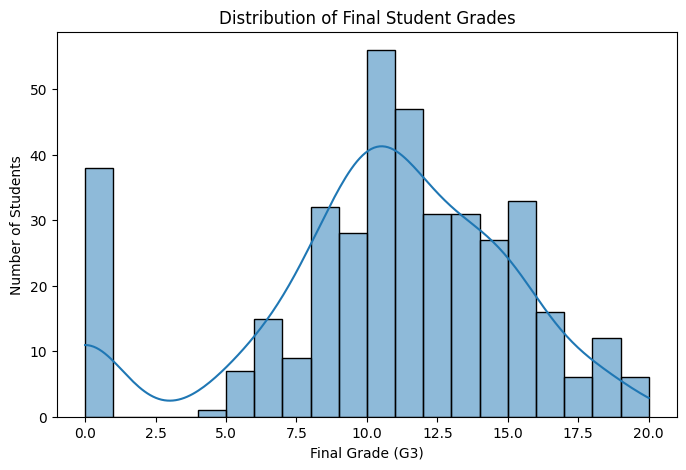

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="G3", bins=20, kde=True)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

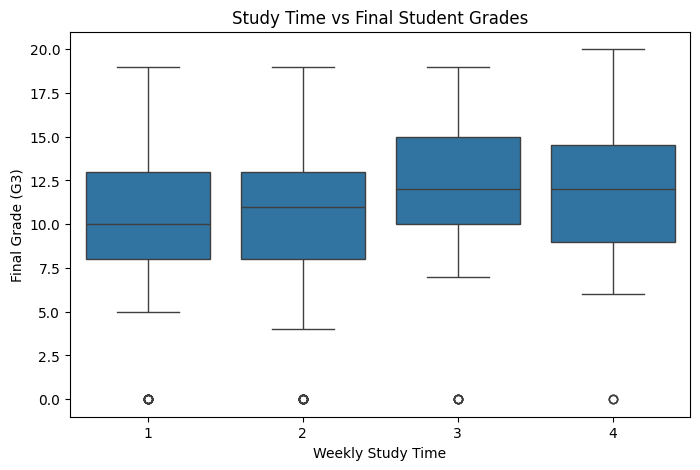

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Student Grades")
plt.xlabel("Weekly Study Time")
plt.ylabel("Final Grade (G3)")

plt.show()

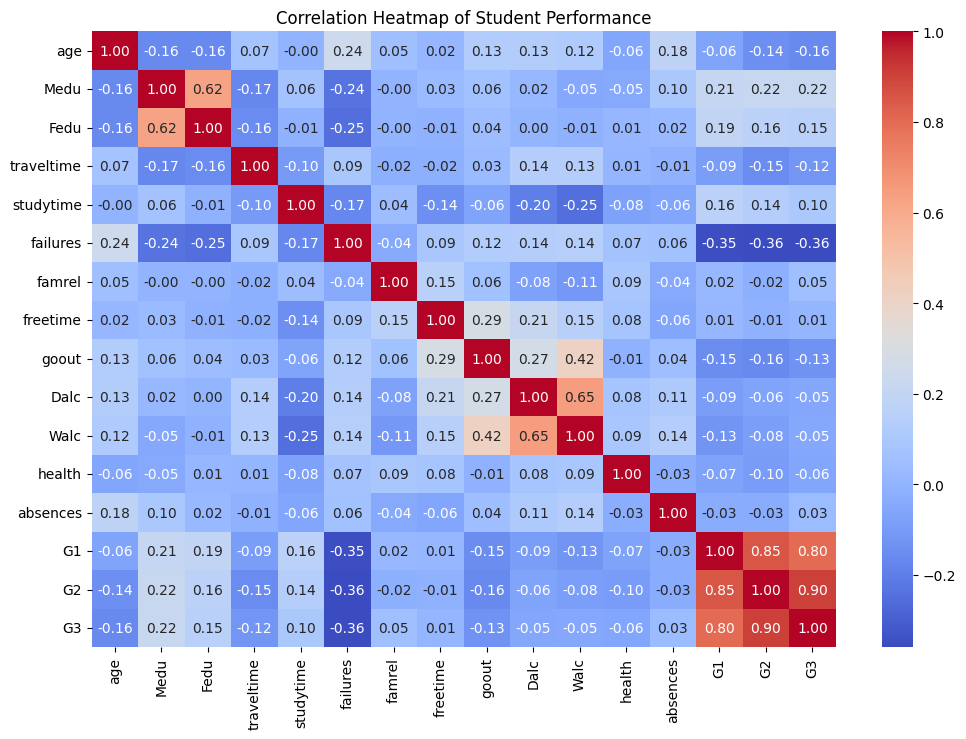

In [14]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Student Performance")

plt.show()

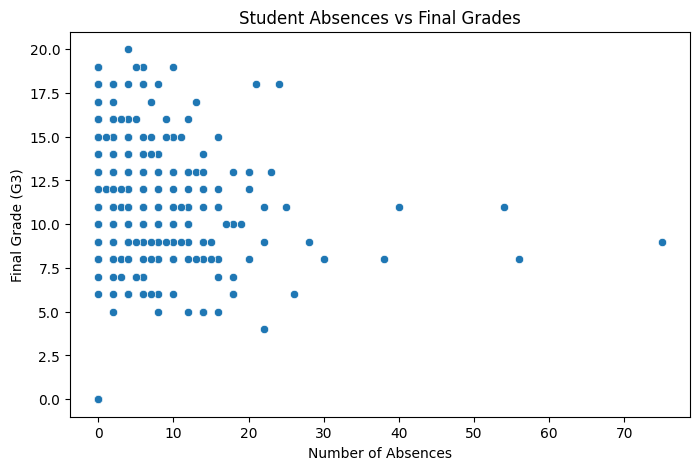

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.show()

In [16]:
# Select the target variable
y = df["G3"]

# Select input features
X = df.drop(columns=["G1", "G2", "G3"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

Features shape: (395, 30)
Target shape: (395,)

Selected features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [17]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nCategorical columns:")
print(categorical_features)

Categorical features: 17
Numerical features: 13

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (316, 30)
Testing features: (79, 30)
Training targets: (316,)
Testing targets: (79,)


In [20]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (316, 56)
Testing data after preprocessing: (79, 56)


In [21]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

linear_predictions = linear_model.predict(X_test_processed)

print("Linear Regression trained successfully!")
print("First 10 predicted grades:")
print(linear_predictions[:10])

Linear Regression trained successfully!
First 10 predicted grades:
[ 1.88508025  7.45339224  8.30868805 11.55112413 10.20284528  9.43314825
 13.21126069 12.69040139 10.26673682 12.34152834]


In [22]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

random_forest_model.fit(X_train_processed, y_train)

rf_predictions = random_forest_model.predict(X_test_processed)

print("Random Forest trained successfully!")
print("First 10 predicted grades:")
print(rf_predictions[:10])

Random Forest trained successfully!
First 10 predicted grades:
[ 9.57   9.315 10.2   12.135  9.895  8.99  14.675 11.355 10.195 12.21 ]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2 Score": [linear_r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.395261,4.195681,0.141492
1,Random Forest,2.993797,3.750812,0.313896


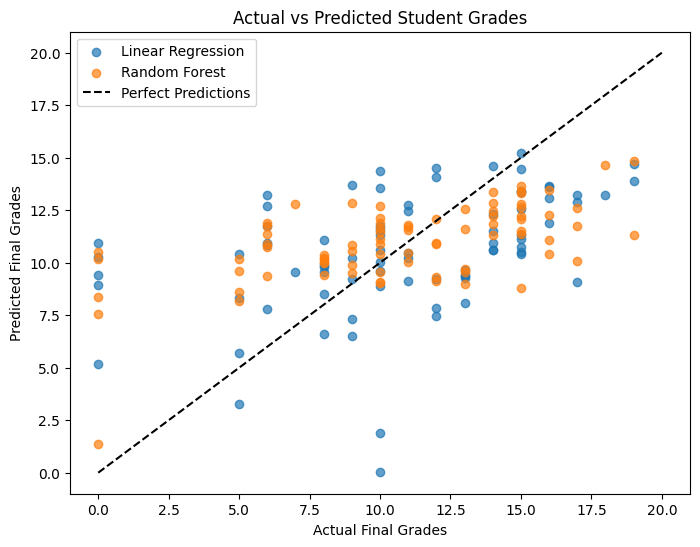

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, linear_predictions, label="Linear Regression", alpha=0.7)
plt.scatter(y_test, rf_predictions, label="Random Forest", alpha=0.7)

plt.plot([0, 20], [0, 20], "k--", label="Perfect Predictions")

plt.xlabel("Actual Final Grades")
plt.ylabel("Predicted Final Grades")
plt.title("Actual vs Predicted Student Grades")
plt.legend()
plt.show()

In [26]:
feature_names = preprocessor.get_feature_names_out()

importance_values = random_forest_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(importance_df.head(10))

Top 10 Important Features:


,Feature,Importance
12,num__absences,0.189617
5,num__failures,0.144544
11,num__health,0.049260
8,num__goout,0.048252
0,num__age,0.037208
4,num__studytime,0.032455
7,num__freetime,0.028539
3,num__traveltime,0.027659
10,num__Walc,0.025525
2,num__Fedu,0.024657


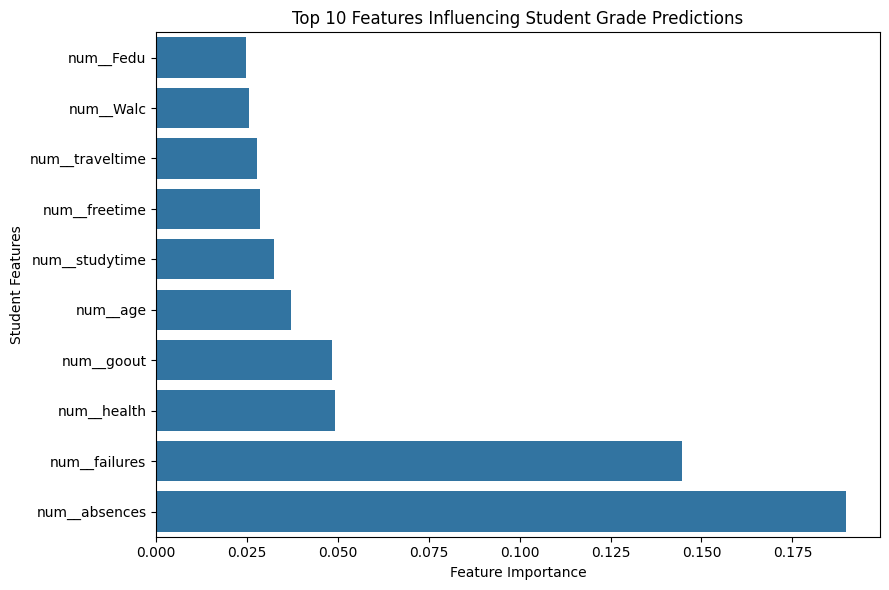

In [27]:
top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Student Grade Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Student Features")
plt.tight_layout()
plt.show()

In [28]:
print("=" * 55)
print("STUDENT PERFORMANCE ANALYTICS AND PREDICTION")
print("=" * 55)

print("\nDataset Information")
print("Total Students:", len(df))
print("Total Features Used:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nModel Comparison")
display(results)

print("\nTop 5 Important Features")
display(importance_df.head(5))

print("\nProject Status: Model training and evaluation completed!")

STUDENT PERFORMANCE ANALYTICS AND PREDICTION

Dataset Information
Total Students: 395
Total Features Used: 30
Training Samples: 316
Testing Samples: 79

Model Comparison


,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.395261,4.195681,0.141492
1,Random Forest,2.993797,3.750812,0.313896



Top 5 Important Features


,Feature,Importance
12,num__absences,0.189617
5,num__failures,0.144544
11,num__health,0.049260
8,num__goout,0.048252
0,num__age,0.037208



Project Status: Model training and evaluation completed!


## Project Findings and Conclusion

### Objective
Develop a machine learning model to predict students' final mathematics grades using demographic, family, social and academic features.

### Dataset
- Dataset: UCI Student Performance (Mathematics)
- Total records: 395 students
- Features used: 30
- Training records: 316
- Testing records: 79
- Target variable: G3 (final grade)

### Models Implemented
1. Linear Regression
2. Random Forest Regression

### Model Evaluation

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| MAE | 3.3953 | 2.9938 |
| RMSE | 4.1957 | 3.7508 |
| R² | 0.1415 | 0.3139 |

Random Forest performed better than Linear Regression across all three evaluation metrics.

### Important Features
The five highest feature-importance scores from the Random Forest model were:
1. Absences
2. Failures
3. Health
4. Going out
5. Age

These scores indicate predictive importance, not causal relationships.

### Conclusion
The project demonstrates how regression algorithms can be used to explore and predict student academic performance. Random Forest achieved better results than Linear Regression on the test dataset, although its predictive performance was moderate.

### Limitations
- The dataset contains only 395 mathematics student records.
- The data comes from two Portuguese schools, so findings may not generalize to other student populations.
- Previous-period grades G1 and G2 were excluded from the input features.
- Predictions should not be treated as definitive assessments of individual students.

### Future Improvements
- Experiment with additional regression algorithms.
- Perform hyperparameter tuning.
- Compare against a simple baseline model.
- Develop an interactive interface for grade predictions.